# Experiment analysis

Analyses the CSV written by experiment mode:

```
py main.py --mode experiment --trees 2 --output results.csv
```

Each row is one (tree, alpha, heuristic). `costRatio` is the heuristic's operation cost divided by the optimum's, and is blank when the heuristic went over the memory limit.

**Setup:** pick your Python 3.12 as the kernel, and install the packages once from a terminal:

```
py -m pip install pandas scikit-learn
```

The cells run from top to bottom. Change `RESULTS` below to analyse another file.

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Notebooks run from their own folder, so the project root is one level up
RESULTS = Path("../results.csv")

# Columns that together identify one tree
TREE_KEYS = ["seed", "nodes", "depthSetting", "widthSetting", "maxChildren", "maxSegmentCost"]
# The tree's measured shape and the memory limit, used to predict the cost ratio
FEATURES = ["nodes", "maxDepth", "maxChildrenFound", "leaves", "maxSegmentCost", "alpha"]

pd.set_option("display.precision", 3)

## Load and clean

A run that was stopped early leaves its last tree with fewer rows than the others, so trees without a row for every alpha and heuristic are dropped.

In [2]:
df = pd.read_csv(RESULTS)

# "none" means no child limit. Keep the column as text so it groups and sorts cleanly
df["maxChildren"] = df["maxChildren"].astype(str)
df["feasible"] = df["feasible"].astype(bool)
df["isOptimal"] = df["isOptimal"].astype(bool)

rowsPerTree = df["alpha"].nunique() * df["heuristic"].nunique()
complete = df.groupby(TREE_KEYS)["heuristic"].transform("size") == rowsPerTree
print(f"Dropped {(~complete).sum()} rows from incomplete trees")
df = df[complete].copy()

print(f"{len(df)} rows, {len(df) // rowsPerTree} trees")
print("Heuristics:", ", ".join(df["heuristic"].unique()))
df.head()

Dropped 4 rows from incomplete trees
287200 rows, 14360 trees
Heuristics: Greedy checkpointing increasing, Greedy checkpointing decreasing, Greedy checkpoint removal increasing, Greedy checkpoint removal decreasing


,seed,nodes,depthSetting,widthSetting,maxChildren,maxSegmentCost,maxDepth,maxChildrenFound,leaves,minMemory,...,optimumMemory,optimumCost,optimumCheckpoints,heuristic,feasible,memory,cost,checkpoints,costRatio,isOptimal
0,0,8,-1.0,-1.0,2,1,3,2,4,3,...,3,15,1 2 3 4 5 7,Greedy checkpointing increasing,True,3,17,1 2 4 6 7,1.133,False
1,0,8,-1.0,-1.0,2,1,3,2,4,3,...,3,15,1 2 3 4 5 7,Greedy checkpointing decreasing,False,4,13,1 2,NaN,False
2,0,8,-1.0,-1.0,2,1,3,2,4,3,...,3,15,1 2 3 4 5 7,Greedy checkpoint removal increasing,True,3,17,1 2 4 6 7,1.133,False
3,0,8,-1.0,-1.0,2,1,3,2,4,3,...,3,15,1 2 3 4 5 7,Greedy checkpoint removal decreasing,True,3,17,1 2 3 4 5 6 7,1.133,False
4,0,8,-1.0,-1.0,2,1,3,2,4,3,...,4,12,1 3 4 5,Greedy checkpointing increasing,True,4,14,2 4 6 7,1.167,False


## Overview per heuristic

Feasibility and quality are kept apart: `feasible` is how often a heuristic met the limit, and the cost ratios only count the rows where it did.

In [3]:
feasibleRows = df[df["feasible"]]

overview = pd.DataFrame({
    "feasible": df.groupby("heuristic")["feasible"].mean(),
    "optimal": df.groupby("heuristic")["isOptimal"].mean(),
    "mean ratio": feasibleRows.groupby("heuristic")["costRatio"].mean(),
    "median ratio": feasibleRows.groupby("heuristic")["costRatio"].median(),
    "worst ratio": feasibleRows.groupby("heuristic")["costRatio"].max(),
})
overview.sort_values("mean ratio")

,feasible,optimal,mean ratio,median ratio,worst ratio
heuristic,,,,,
Greedy checkpointing increasing,1.000,0.344,1.094,1.045,1.911
Greedy checkpoint removal decreasing,1.000,0.285,1.258,1.084,4.869
Greedy checkpoint removal increasing,1.000,0.307,1.292,1.113,4.500
Greedy checkpointing decreasing,0.938,0.265,1.636,1.178,6.310


## Effect of the memory limit (alpha)

alpha 0 is the tightest limit any choice can meet, and alpha 1 needs no checkpoints at all.

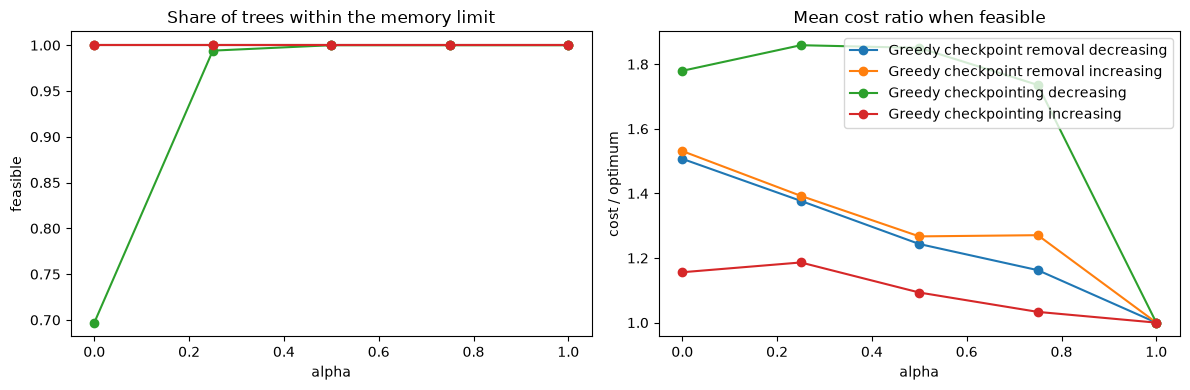

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))

for name, group in df.groupby("heuristic"):
    left.plot(group.groupby("alpha")["feasible"].mean(), marker="o", label=name)
    right.plot(group[group["feasible"]].groupby("alpha")["costRatio"].mean(), marker="o", label=name)

left.set(title="Share of trees within the memory limit", xlabel="alpha", ylabel="feasible")
right.set(title="Mean cost ratio when feasible", xlabel="alpha", ylabel="cost / optimum")
right.legend()
plt.tight_layout()
plt.show()

## Effect of each setting

Mean cost ratio (feasible rows only) against one setting at a time, averaged over everything else.

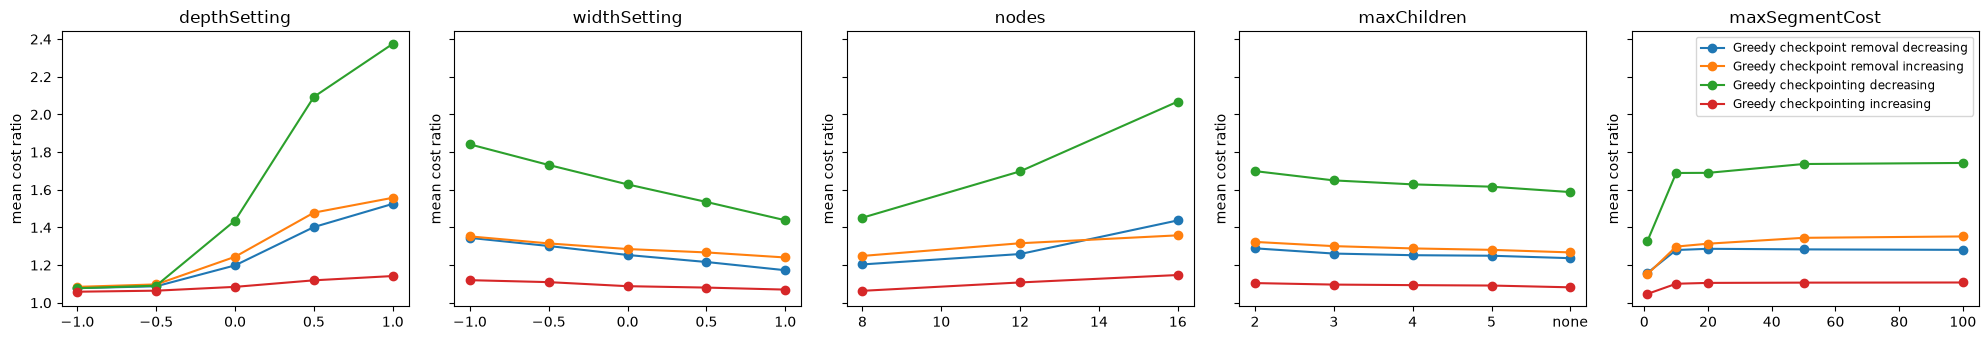

In [5]:
def plot_by(column, ax):
    for name, group in feasibleRows.groupby("heuristic"):
        ax.plot(group.groupby(column)["costRatio"].mean(), marker="o", label=name)
    ax.set(title=column, ylabel="mean cost ratio")


columns = ["depthSetting", "widthSetting", "nodes", "maxChildren", "maxSegmentCost"]
fig, axes = plt.subplots(1, len(columns), figsize=(4 * len(columns), 3.5), sharey=True)
for column, ax in zip(columns, axes):
    plot_by(column, ax)
axes[-1].legend(fontsize="small")
plt.tight_layout()
plt.show()

## Tree shape: depth x width

Mean cost ratio for each combination of the depth and width settings, one map per heuristic, on a shared colour scale. Set `ALPHA` to one value (e.g. `0.25`) to look at one memory limit only, or leave it as `None` for all of them.

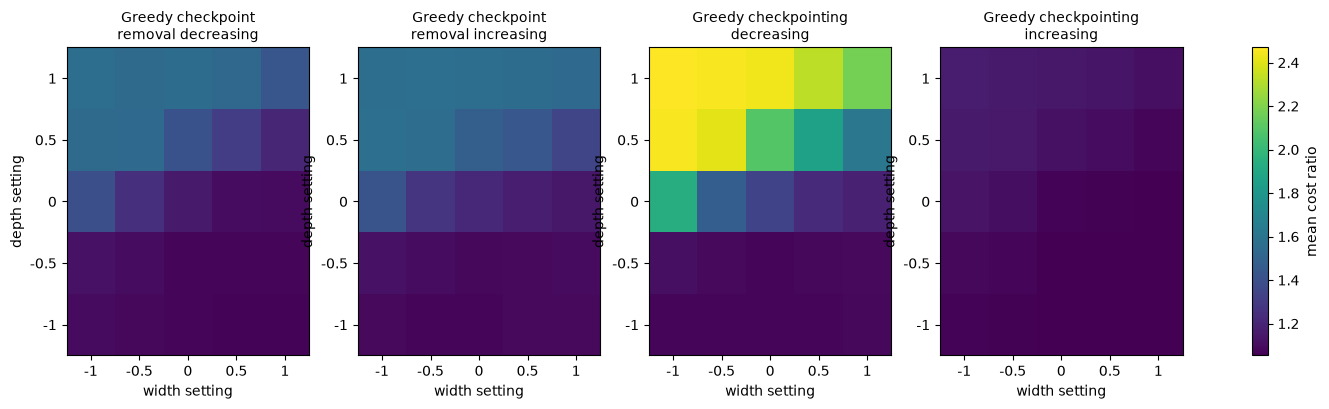

In [6]:
ALPHA = None

rows = feasibleRows if ALPHA is None else feasibleRows[feasibleRows["alpha"] == ALPHA]
heuristics = sorted(rows["heuristic"].unique())
maps = {name: rows[rows["heuristic"] == name]
        .pivot_table(index="depthSetting", columns="widthSetting", values="costRatio", aggfunc="mean")
        for name in heuristics}
low = min(m.min().min() for m in maps.values())
high = max(m.max().max() for m in maps.values())

fig, axes = plt.subplots(1, len(heuristics), figsize=(4.5 * len(heuristics), 4), squeeze=False)
for ax, name in zip(axes[0], heuristics):
    m = maps[name]
    image = ax.imshow(m.values, origin="lower", vmin=low, vmax=high, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(m.columns)), [f"{v:g}" for v in m.columns])
    ax.set_yticks(range(len(m.index)), [f"{v:g}" for v in m.index])
    ax.set(xlabel="width setting", ylabel="depth setting")
    ax.set_title(textwrap.fill(name, 22), fontsize="medium")
fig.colorbar(image, ax=axes[0].tolist(), label="mean cost ratio")
plt.show()

## Worst cases

The rows furthest from the optimum, with the command that redraws each tree in random mode (run it from the project folder).

In [7]:
def rebuild_command(row):
    command = (f"python main.py --mode random --seed {row.seed} --nodes {row.nodes} "
               f"--depth {row.depthSetting:g} --width {row.widthSetting:g} "
               f"--max-segment-cost {row.maxSegmentCost} --alpha {row.alpha:g}")
    if row.maxChildren != "none":
        command += f" --max-children {row.maxChildren}"
    return command


worst = feasibleRows.nlargest(10, "costRatio")
for row in worst.itertuples():
    print(f"{row.costRatio:.2f}  {row.heuristic}")
    print("      ", rebuild_command(row))

worst[TREE_KEYS + ["alpha", "heuristic", "cost", "optimumCost", "costRatio"]]

6.31  Greedy checkpointing decreasing
       python main.py --mode random --seed 1 --nodes 16 --depth 0.5 --width -1 --max-segment-cost 50 --alpha 0.5 --max-children 2
6.31  Greedy checkpointing decreasing
       python main.py --mode random --seed 1 --nodes 16 --depth 0.5 --width -1 --max-segment-cost 50 --alpha 0.5 --max-children 3
6.31  Greedy checkpointing decreasing
       python main.py --mode random --seed 1 --nodes 16 --depth 0.5 --width -1 --max-segment-cost 50 --alpha 0.5 --max-children 4
6.31  Greedy checkpointing decreasing
       python main.py --mode random --seed 1 --nodes 16 --depth 0.5 --width -1 --max-segment-cost 50 --alpha 0.5 --max-children 5
6.31  Greedy checkpointing decreasing
       python main.py --mode random --seed 1 --nodes 16 --depth 0.5 --width -1 --max-segment-cost 50 --alpha 0.5
6.31  Greedy checkpointing decreasing
       python main.py --mode random --seed 1 --nodes 16 --depth 1 --width -0.5 --max-segment-cost 50 --alpha 0.5 --max-children 2
6.31  Gre

,seed,nodes,depthSetting,widthSetting,maxChildren,maxSegmentCost,alpha,heuristic,cost,optimumCost,costRatio
270069,1,16,0.5,-1.0,2,50,0.5,Greedy checkpointing decreasing,5894,934,6.31
270169,1,16,0.5,-1.0,3,50,0.5,Greedy checkpointing decreasing,5894,934,6.31
270269,1,16,0.5,-1.0,4,50,0.5,Greedy checkpointing decreasing,5894,934,6.31
270369,1,16,0.5,-1.0,5,50,0.5,Greedy checkpointing decreasing,5894,934,6.31
270469,1,16,0.5,-1.0,none,50,0.5,Greedy checkpointing decreasing,5894,934,6.31
273069,1,16,1.0,-0.5,2,50,0.5,Greedy checkpointing decreasing,5894,934,6.31
273169,1,16,1.0,-0.5,3,50,0.5,Greedy checkpointing decreasing,5894,934,6.31
273269,1,16,1.0,-0.5,4,50,0.5,Greedy checkpointing decreasing,5894,934,6.31
273369,1,16,1.0,-0.5,5,50,0.5,Greedy checkpointing decreasing,5894,934,6.31
273469,1,16,1.0,-0.5,none,50,0.5,Greedy checkpointing decreasing,5894,934,6.31


## What drives the gap?

A gradient boosting model per heuristic predicts the cost ratio from the tree's measured shape and the memory limit. The cross-validated R² says how well that works (1 is perfect, 0 is no better than guessing the average), and feature importance shows which inputs matter most. Only feasible rows are used.

Greedy checkpoint removal decreasing: cross-validated R^2 = 0.47
Greedy checkpoint removal increasing: cross-validated R^2 = 0.52
Greedy checkpointing decreasing: cross-validated R^2 = 0.83
Greedy checkpointing increasing: cross-validated R^2 = 0.57


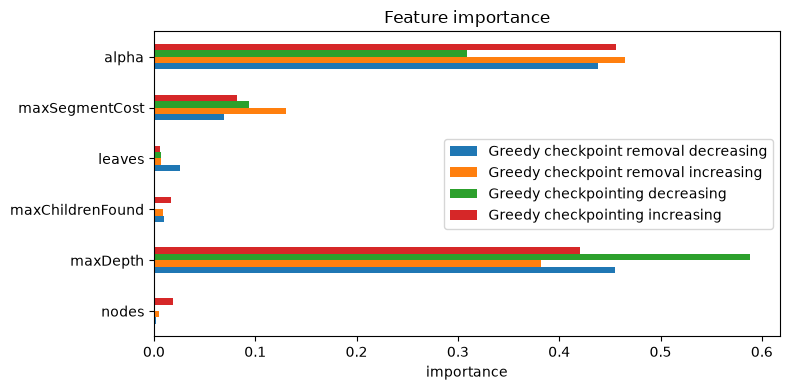

,Greedy checkpoint removal decreasing,Greedy checkpoint removal increasing,Greedy checkpointing decreasing,Greedy checkpointing increasing
nodes,0.002,0.005,1.391e-03,0.019
maxDepth,0.455,0.383,5.885e-01,0.421
maxChildrenFound,0.010,0.009,6.801e-04,0.017
leaves,0.025,0.007,6.613e-03,0.006
maxSegmentCost,0.069,0.130,9.374e-02,0.082
alpha,0.438,0.465,3.091e-01,0.456


In [8]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score

importances = {}
for name, group in feasibleRows.groupby("heuristic"):
    X, y = group[FEATURES], group["costRatio"]
    model = GradientBoostingRegressor(random_state=0)
    score = cross_val_score(model, X, y, cv=5, scoring="r2").mean()
    model.fit(X, y)
    importances[name] = pd.Series(model.feature_importances_, index=FEATURES)
    print(f"{name}: cross-validated R^2 = {score:.2f}")

importances = pd.DataFrame(importances)
importances.plot.barh(figsize=(8, 4), title="Feature importance")
plt.xlabel("importance")
plt.tight_layout()
plt.show()
importances